<a href="https://colab.research.google.com/github/ialipon/ENCH680PRJ/blob/main/PRJ_knn-sec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project - KNN

**Objectives**

By the end of this session, we will be able to:

First Stage
- Use KNN modeling for classification.
- Prepare a research dataset for classification: clean it to exclude data that are to be excluded and turn Recovery% into desirable/undesirable labels
  - Predict Recovery% is desirable or undesirable for provided data input variable.
- Train a K-Nearest Neighbors (KNN) classifier with scikit-learn and evaluate it with test accuracy
- Tune KNN hyperparameters (`n_neighbors`, `weights`) by comparing test accuracy across values of `k`
- Explain why KNN needs feature scaling, and compare models trained with and without `StandardScaler`

Second stage:
- Use KNN modeling for regression


## 1. Import python packages: matplotlib, pandas, numpy

In [76]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Read CO2 capture data from xlsx file

In [77]:
data_file_path = "https://github.com/ialipon/ENCH680PRJ/raw/main/Dataset.xlsx"
Rec_data = pd.read_excel(data_file_path)

## 3. Prepare Dataset

In the dataset, we can see that there are eight input columns and three output columns where the output columns are "Recovery%", "SEC", and "CO2 Purity". All these three output columns will be excluded as input variable.

For the KNN classification, we will use Recovery% as the target output where:
- Recovery ≥ 80%: Desirable.
- Recovery below 80%: Not Desirable.
This will evaluate whether the operating parameters can identify desirable conditions.

For the KNN regression, we will use the desired operating parameters to evaluate SEC prediction.


In [78]:
print(Rec_data.head(10))

   Fluegas CO2 mol%  Fluegas Flow (kg/h)  Lean Solvent Flow (kg/h)  \
0               2.0              1500000             799999.978656   
1               2.5              1500000             800000.056029   
2               3.0              1500000             800000.046691   
3               3.5              1500000             800000.030682   
4               4.0              1500000             800000.038687   
5               4.5              1500000             800000.028014   
6               2.0              3100000             800000.010672   
7               2.5              3100000             799999.997332   
8               3.0              3100000             800000.004002   
9               3.5              3100000             800000.000000   

   Lean Solvent Loading Amine type  Amine Conc (wt%)  Lean Solvent T (C)  \
0              0.549078        MEA         14.992197                  37   
1              0.684311        MEA         14.992198                  37   
2

## 4. Stage 1 - KNN Classification

Let's define and assign Desirable Recovery%
- Recovery ≥ 80%: Desirable.
- Recovery < 80%: Not Desirable.

In [79]:
# Create new classification column

Rec_data["Classification"] = np.where(
    Rec_data["Recovery%"] >= 80,
    "Desirable",
    "Not Desirable"
)

# Display the results
print(Rec_data.head(10))

# Save the updated dataset
Rec_data.to_excel("Dataset_with_Classification.xlsx", index=False)

   Fluegas CO2 mol%  Fluegas Flow (kg/h)  Lean Solvent Flow (kg/h)  \
0               2.0              1500000             799999.978656   
1               2.5              1500000             800000.056029   
2               3.0              1500000             800000.046691   
3               3.5              1500000             800000.030682   
4               4.0              1500000             800000.038687   
5               4.5              1500000             800000.028014   
6               2.0              3100000             800000.010672   
7               2.5              3100000             799999.997332   
8               3.0              3100000             800000.004002   
9               3.5              3100000             800000.000000   

   Lean Solvent Loading Amine type  Amine Conc (wt%)  Lean Solvent T (C)  \
0              0.549078        MEA         14.992197                  37   
1              0.684311        MEA         14.992198                  37   
2

## 5. Understand how the data looks like using scatter plots

- [Main reference for matplotlib point styling](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html)
- [Color names you can use](https://matplotlib.org/stable/gallery/color/named_colors.html)
- [Marker shapes](https://matplotlib.org/stable/api/markers_api.html)
- [Color maps](https://matplotlib.org/stable/users/explain/colors/colormaps.html)

### 5.1 Fluegas CO2 mol% vs CO2 Recovery %



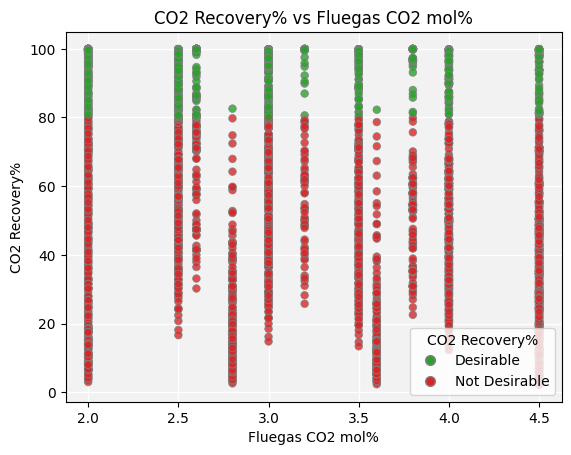

In [80]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Fluegas CO2 mol%",
    y="Recovery%",
    title="CO2 Recovery% vs Fluegas CO2 mol%",
    grid=True,

    label="Recovery per Fluegas CO2 mol",
    xlabel="Fluegas CO2 mol%",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.2 Fluegas Flow

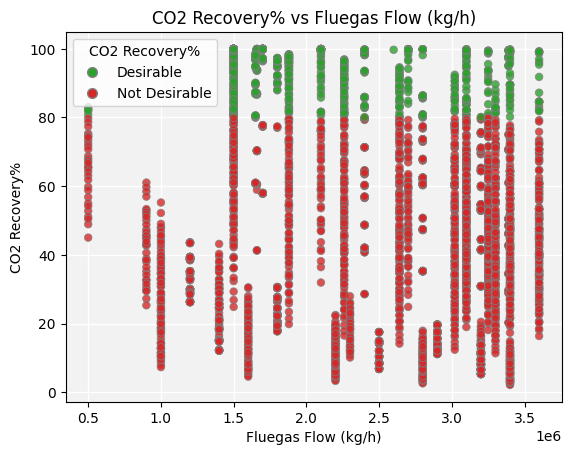

In [81]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Fluegas Flow (kg/h)",
    y="Recovery%",
    title="CO2 Recovery% vs Fluegas Flow (kg/h)",
    grid=True,

    label="Recovery per Fluegas Flow",
    xlabel="Fluegas Flow (kg/h)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.3 Lean Solvent Flow

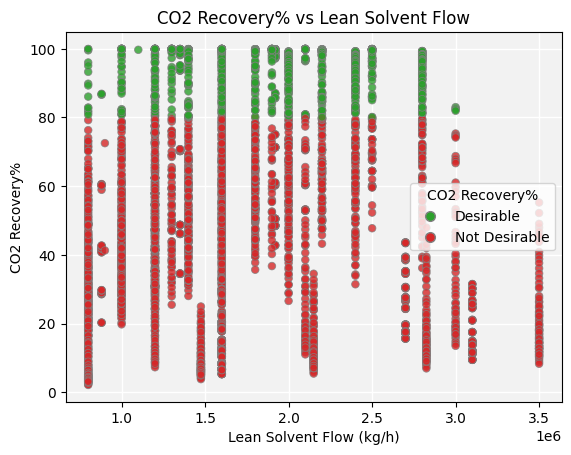

In [82]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Lean Solvent Flow (kg/h)",
    y="Recovery%",
    title="CO2 Recovery% vs Lean Solvent Flow",
    grid=True,

    label="Recovery per Lean Solvent Flow",
    xlabel="Lean Solvent Flow (kg/h)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.4 Lean Solvent Loading

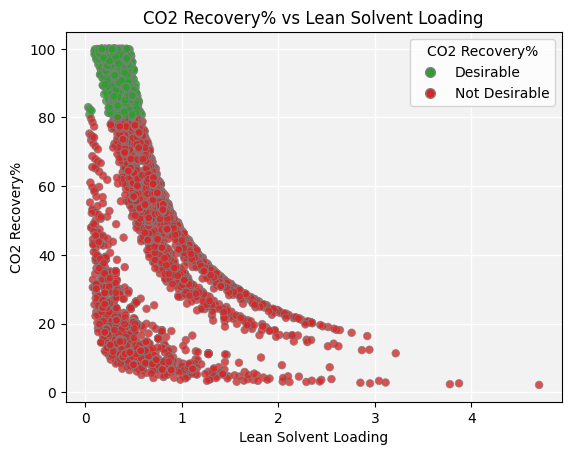

In [83]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Lean Solvent Loading",
    y="Recovery%",
    title="CO2 Recovery% vs Lean Solvent Loading",
    grid=True,

    label="Recovery per Lean Solvent Loading",
    xlabel="Lean Solvent Loading",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.5 Amine Type

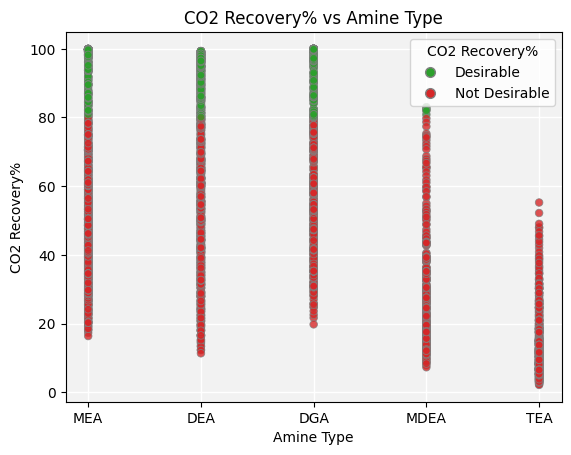

In [84]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Amine type",
    y="Recovery%",
    title="CO2 Recovery% vs Amine Type",
    grid=True,
    label="Recovery per Amine Type",
    xlabel="Amine Type",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.6 Amine Concentration

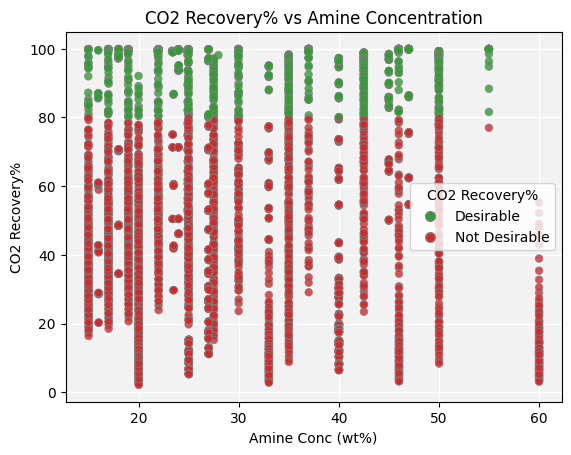

In [85]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Amine Conc (wt%)",
    y="Recovery%",
    title="CO2 Recovery% vs Amine Concentration",
    grid=True,

    label="Recovery per Amine Conc (wt%)",
    xlabel="Amine Conc (wt%)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.7 Lean Solvent Temperature

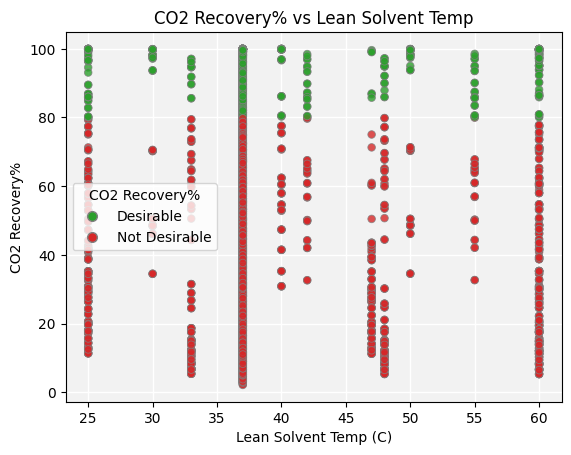

In [86]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Lean Solvent T (C)",
    y="Recovery%",
    title="CO2 Recovery% vs Lean Solvent Temp",
    grid=True,
    logx=False,
    label="Recovery per Lean Solvent Temp",
    xlabel="Lean Solvent Temp (C)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 5.8 Reboiler Duty

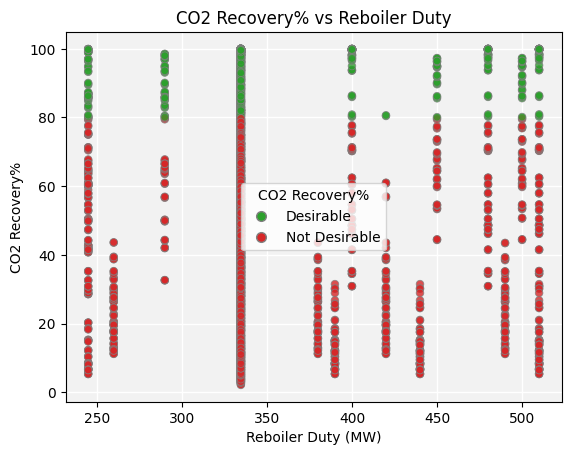

In [87]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Reboiler Duty (MW)",
    y="Recovery%",
    title="CO2 Recovery% vs Reboiler Duty",
    grid=True,
    logx=False,
    label="Recovery vs Reboiler Duty",
    xlabel="Reboiler Duty (MW)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### TEST - Combination Plot
Show relationship of two input variable to Desirable/Not Desirable classified Recovery% output.

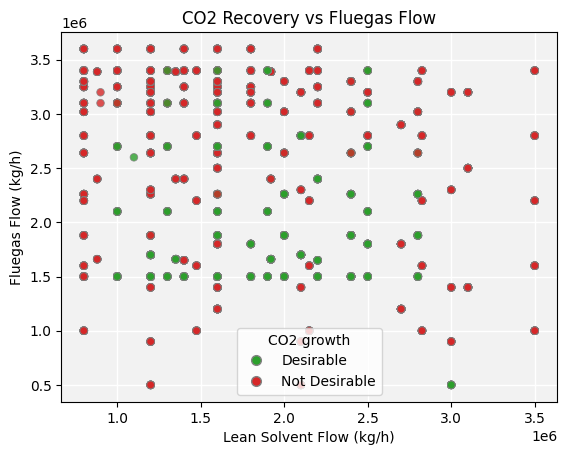

In [88]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Lean Solvent Flow (kg/h)",
    y="Fluegas Flow (kg/h)",
    title="CO2 Recovery vs Fluegas Flow",
    grid=True,
    logx=False,
    logy=False,
    xlabel="Lean Solvent Flow (kg/h)",
    ylabel="Fluegas Flow (kg/h)",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 growth")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

## 6. Build a KNN model

##6.1 Define a problem:
Predict Recovery% if Desirable or Not Desirable for each run based on eight input variables.

Input:
- Fluegas CO2 mol%
- Fluegas Flow (kg/h)
- Lean Solvent Flow (kg/h)
- Lean Solvent Loading
- Amine Type
- Amine Conc (w%)
- Lean Solvent T (C)
- Reboiler Duty (MW)

Output:
- CO2 Recovery%:  Desirable (% ≥ 80), Not Desirable (% < 80)

Data ignored:
- SEC (kJ/kg)
- CO2 Purity (mol%)

In [89]:
# Load dataset
df = pd.read_excel("https://github.com/ialipon/ENCH680PRJ/raw/main/Dataset.xlsx")

# Classification target
y_class = np.where(
    df["Recovery%"] >= 80,
    "Desirable",
    "Not Desirable"
)

# Eight input variables
X_with_duty = df.drop(columns=[
    "Recovery%",
    "SEC (kJ/kg)",
    "CO2 Purity (mol%)"
])

# One-hot encode categorical features (Amine type)
X_encoded = pd.get_dummies(X_with_duty, columns=["Amine type"], drop_first=True)

print("Classification distribution:")
print(pd.Series(y_class).value_counts())

print("Dataset size:", len(df))
print("Encoded features columns:", list(X_encoded.columns))

Classification distribution:
Not Desirable    3272
Desirable        1154
Name: count, dtype: int64
Dataset size: 4426
Encoded features columns: ['Fluegas CO2 mol%', 'Fluegas Flow (kg/h)', 'Lean Solvent Flow (kg/h)', 'Lean Solvent Loading', 'Amine Conc (wt%)', 'Lean Solvent T (C)', 'Reboiler Duty (MW)', 'Amine type_DGA', 'Amine type_MDEA', 'Amine type_MEA', 'Amine type_TEA']


### 6.2 Split dataset into Training and Testing

`train_test_split`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [90]:
from sklearn.model_selection import train_test_split

X_train, X_test, \
y_class_train, y_class_test, \
= train_test_split(
    X_encoded,
    y_class,
    test_size=0.20,
    random_state=29,
    stratify=y_class
)

In [91]:
from sklearn.model_selection import train_test_split

# Correcting to use the active carbon capture dataset variables
X = X_encoded
y = y_class

X_train, X_test, y_class_train, y_class_test = train_test_split(
    X, y, test_size=0.20, random_state=29, stratify=y
)

In [92]:
### Train-Test Split Summary
print("### Train-Test Split Summary")
print(f"Overall dataset shape: {X_encoded.shape}")
print(
    f"Training set shape: {X_train.shape}, percentage: {X_train.shape[0] / X_encoded.shape[0]:.2%}"
)
print(f"Test set shape: {X_test.shape}, percentage: {X_test.shape[0] / X_encoded.shape[0]:.2%}")

### Train-Test Split Summary
Overall dataset shape: (4426, 11)
Training set shape: (3540, 11), percentage: 79.98%
Test set shape: (886, 11), percentage: 20.02%


### 6.3 Build the KNN classifier

`KNeighborsClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

In [93]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

estimator = KNeighborsClassifier(
    n_neighbors=9,
    weights="uniform",  # or "distance"
    algorithm="auto",  # or "ball_tree", "kd_tree", "brute"
)

estimator.fit(X_train, y_class_train)
y_pred = estimator.predict(X_test)
accuracy = accuracy_score(y_class_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 89.73%


In [94]:
y_pred_df = pd.DataFrame(
    {"y_test": y_class_test, "y_pred": y_pred, "correct": y_class_test == y_pred}
)

In [95]:
y_pred_df.head(10)
# y_pred_df.loc[y_pred_df["correct"]].shape[0] * 100/ y_pred_df.shape[0]

,y_test,y_pred,correct
0,Desirable,Not Desirable,False
1,Desirable,Desirable,True
2,Desirable,Desirable,True
3,Not Desirable,Not Desirable,True
4,Not Desirable,Not Desirable,True
5,Not Desirable,Not Desirable,True
6,Desirable,Desirable,True
7,Desirable,Desirable,True
8,Desirable,Desirable,True
9,Not Desirable,Desirable,False


### 6.4 Model's Hyper-parameters tuning

In [96]:
metrics = pd.DataFrame(
    {
        "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
        "uniform_accuracy": [None] * 12,
        "distance_accuracy": [None] * 12,
    }
)
metrics.head()

,n_neighbors,uniform_accuracy,distance_accuracy
0,1,None,None
1,3,None,None
2,5,None,None
3,7,None,None
4,9,None,None


In [97]:
# Initialize metrics if not already defined
if 'metrics' not in globals():
    metrics = pd.DataFrame(
        {
            "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
            "uniform_accuracy": [None] * 12,
            "distance_accuracy": [None] * 12,
        }
    )

for weights in ["uniform", "distance"]:
    print(f"##### Training KNN with weights={weights}")
    for i, n_neighbors in enumerate(metrics["n_neighbors"]):
        estimator = KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights=weights,
            algorithm="auto",
        )

        estimator.fit(X_train, y_class_train)
        y_pred = estimator.predict(X_test)
        accuracy = accuracy_score(y_class_test, y_pred)
        if weights == "uniform":
            metrics.loc[i, "uniform_accuracy"] = accuracy
        else:
            metrics.loc[i, "distance_accuracy"] = accuracy
        print(
            f"Training KNN with n_neighbors={n_neighbors} and weights={weights}, accuracy={accuracy:.4f}"
        )

##### Training KNN with weights=uniform
Training KNN with n_neighbors=1 and weights=uniform, accuracy=0.9086
Training KNN with n_neighbors=3 and weights=uniform, accuracy=0.8894
Training KNN with n_neighbors=5 and weights=uniform, accuracy=0.8928
Training KNN with n_neighbors=7 and weights=uniform, accuracy=0.8950
Training KNN with n_neighbors=9 and weights=uniform, accuracy=0.8973
Training KNN with n_neighbors=11 and weights=uniform, accuracy=0.8950
Training KNN with n_neighbors=13 and weights=uniform, accuracy=0.8916
Training KNN with n_neighbors=15 and weights=uniform, accuracy=0.8849
Training KNN with n_neighbors=17 and weights=uniform, accuracy=0.8758
Training KNN with n_neighbors=19 and weights=uniform, accuracy=0.8725
Training KNN with n_neighbors=21 and weights=uniform, accuracy=0.8634
Training KNN with n_neighbors=23 and weights=uniform, accuracy=0.8646
##### Training KNN with weights=distance
Training KNN with n_neighbors=1 and weights=distance, accuracy=0.9086
Training KNN w

In [98]:
metrics

,n_neighbors,uniform_accuracy,distance_accuracy
0,1,0.908578,0.908578
1,3,0.889391,0.900677
2,5,0.892777,0.901806
3,7,0.895034,0.895034
4,9,0.897291,0.896163
5,11,0.895034,0.895034
6,13,0.891648,0.892777
7,15,0.884876,0.895034
8,17,0.875847,0.892777
9,19,0.87246,0.893905


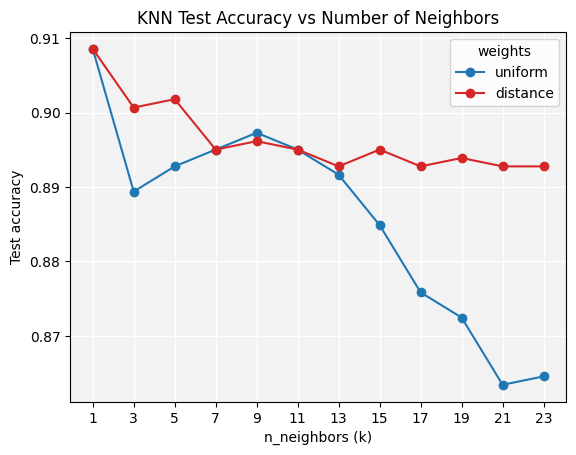

In [99]:
fig, ax = plt.subplots()

# The accuracy columns started as None, so convert them to numbers before plotting
ax.plot(
    metrics["n_neighbors"],
    metrics["uniform_accuracy"].astype(float),
    marker="o",
    color="tab:blue",
    label="uniform",
)
ax.plot(
    metrics["n_neighbors"],
    metrics["distance_accuracy"].astype(float),
    marker="o",
    color="tab:red",
    label="distance",
)

ax.set_title("KNN Test Accuracy vs Number of Neighbors")
ax.set_xlabel("n_neighbors (k)")
ax.set_ylabel("Test accuracy")
ax.set_xticks(metrics["n_neighbors"])
ax.legend(title="weights")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 6.5 Why applying scaler to the input dataset?

In [100]:
metrics_scaling = pd.DataFrame(
    {
        "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
        "without_scaling": [None] * 12,
        "with_scaling": [None] * 12,
    }
)
metrics_scaling.head()

,n_neighbors,without_scaling,with_scaling
0,1,None,None
1,3,None,None
2,5,None,None
3,7,None,None
4,9,None,None


In [101]:
# apply StandardScaler to the features before fitting the KNN model

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [102]:
# Initialize metrics_scaling if not already defined
if 'metrics_scaling' not in globals():
    metrics_scaling = pd.DataFrame(
        {
            "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
            "without_scaling": [None] * 12,
            "with_scaling": [None] * 12,
        }
    )

# Ensure scaled features are defined if scaling cell was skipped
if 'X_train_scaled' not in globals() or 'X_test_scaled' not in globals():
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

for model in ["without_scaling", "with_scaling"]:
    print(f"##### Training KNN with model={model}")
    for i, n_neighbors in enumerate(metrics_scaling["n_neighbors"]):
        estimator = KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights="uniform",
            algorithm="auto",
        )

        if model == "with_scaling":
            estimator.fit(X_train_scaled, y_class_train)
            y_pred = estimator.predict(X_test_scaled)
        else:
            estimator.fit(X_train, y_class_train)
            y_pred = estimator.predict(X_test)

        accuracy = accuracy_score(y_class_test, y_pred)
        if model == "without_scaling":
            metrics_scaling.loc[i, "without_scaling"] = accuracy
        else:
            metrics_scaling.loc[i, "with_scaling"] = accuracy
        print(
            f"Training KNN with n_neighbors={n_neighbors} and model={model}, accuracy={accuracy:.4f}"
        )

##### Training KNN with model=without_scaling
Training KNN with n_neighbors=1 and model=without_scaling, accuracy=0.9086
Training KNN with n_neighbors=3 and model=without_scaling, accuracy=0.8894
Training KNN with n_neighbors=5 and model=without_scaling, accuracy=0.8928
Training KNN with n_neighbors=7 and model=without_scaling, accuracy=0.8950
Training KNN with n_neighbors=9 and model=without_scaling, accuracy=0.8973
Training KNN with n_neighbors=11 and model=without_scaling, accuracy=0.8950
Training KNN with n_neighbors=13 and model=without_scaling, accuracy=0.8916
Training KNN with n_neighbors=15 and model=without_scaling, accuracy=0.8849
Training KNN with n_neighbors=17 and model=without_scaling, accuracy=0.8758
Training KNN with n_neighbors=19 and model=without_scaling, accuracy=0.8725
Training KNN with n_neighbors=21 and model=without_scaling, accuracy=0.8634
Training KNN with n_neighbors=23 and model=without_scaling, accuracy=0.8646
##### Training KNN with model=with_scaling
Trai

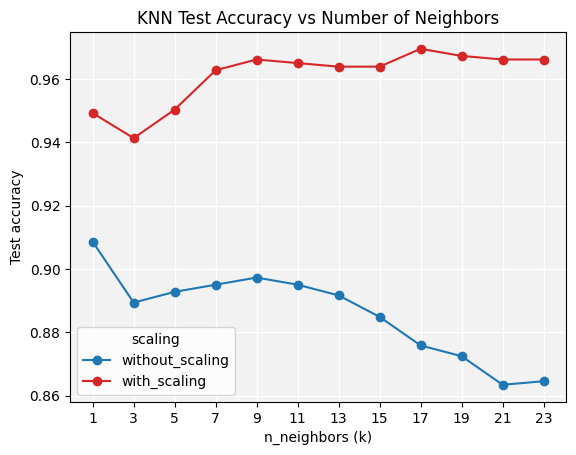

In [103]:
fig, ax = plt.subplots()

# The accuracy columns started as None, so convert them to numbers before plotting
ax.plot(
    metrics_scaling["n_neighbors"],
    metrics_scaling["without_scaling"].astype(float),
    marker="o",
    color="tab:blue",
    label="without_scaling",
)
ax.plot(
    metrics_scaling["n_neighbors"],
    metrics_scaling["with_scaling"].astype(float),
    marker="o",
    color="tab:red",
    label="with_scaling",
)

ax.set_title("KNN Test Accuracy vs Number of Neighbors")
ax.set_xlabel("n_neighbors (k)")
ax.set_ylabel("Test accuracy")
ax.set_xticks(metrics_scaling["n_neighbors"])
ax.legend(title="scaling")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

## 7. Save the cleaned datasets into file

In [104]:
Rec_data.to_excel("co2_classification.xlsx", index=False)

#8. Stage 2 - KNN Regression